# Scouting com dados: encontrando jogadores com perfil parecido

**Pergunta de negócio:** um clube perdeu um jogador importante (ou não consegue pagar por ele). Quais atletas têm o **perfil estatístico mais parecido** e podem entrar numa lista curta para o departamento de scouting assistir?

**Dados:** eventos da [StatsBomb Open Data](https://github.com/statsbomb/open-data) de 4 torneios de seleções entre 2022 e 2024 (Copa do Mundo 2022, Euro 2024, Copa América 2024 e Copa Africana 2023), com 199 partidas e cerca de 1.700 jogadores.

**Método:**
1. Calcular os minutos jogados de cada atleta a partir dos eventos (titulares, substituições e expulsões).
2. Calcular cerca de 20 métricas **por 90 minutos** (xG, xA, ações progressivas, dribles, pressões etc.).
3. Padronizar as métricas por z-score **dentro da posição** e medir a **similaridade de cosseno** entre jogadores.
4. Visualizar perfis com **barras de percentil** por fase do jogo.

In [1]:
import sys; sys.path.append("..")
import pandas as pd
from pathlib import Path
from src.features import build_player_table
from src.similarity import find_similar, pool, LABELS
from src import viz

pd.set_option("display.precision", 2)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

csv = Path("../data/processed/player_stats.csv")
# Na primeira execução, baixa os dados da StatsBomb (~550 MB) e gera a tabela.
df = pd.read_csv(csv) if csv.exists() else build_player_table()
print(f"{len(df)} jogadores · {df['matches'].max()} jogos no máximo por jogador")

1717 jogadores · 13 jogos no máximo por jogador


## 1. Visão geral da amostra

Como são torneios curtos, a minutagem varia muito. Para a análise, uso um corte de **270 minutos** (equivalente a 3 jogos completos), para que as métricas por 90 não fiquem distorcidas por amostras pequenas.

In [2]:
MIN_MIN = 270
nomes = {"GOL": "Goleiro", "ZAG": "Zagueiro", "LAT": "Lateral", "VOL": "Volante",
         "MEI": "Meia", "PON": "Ponta", "ATA": "Centroavante"}
resumo = (df[df["minutes"] >= MIN_MIN].groupby("group")
          .agg(jogadores=("player", "count"), minutos_mediana=("minutes", "median"))
          .rename(index=nomes).sort_values("jogadores", ascending=False))
resumo

,jogadores,minutos_mediana
group,,
Zagueiro,166,404.5
Lateral,124,407.0
Volante,94,419.5
Ponta,85,393.0
Meia,78,400.5
Goleiro,73,401.0
Centroavante,63,374.0


## 2. Caso 1: quem tem o perfil mais parecido com Vinícius Júnior?

Pontas são comparados apenas com pontas. A similaridade vai de -100 a 100, e 100 significa um perfil idêntico.

In [3]:
similares_vini = find_similar(df, "Vinícius Júnior", min_minutes=MIN_MIN, n=10)
similares_vini

,player,team,position,minutes,similarity
0,Jérémy Doku,Belgium,Left Wing,354,80.8
1,Jamal Musiala,Germany,Left Wing,731,73.9
2,Kylian Mbappé,France,Left Wing,1180,70.6
3,Rafael Leão,Portugal,Left Wing,420,65.9
4,Raphinha,Brazil,Right Wing,620,58.8
5,Lamine Yamal,Spain,Right Wing,531,57.6
6,Simon Adingra,Côte d'Ivoire,Left Wing,312,46.2
7,Ismaïla Sarr,Senegal,Left Wing,738,44.7
8,Christian Pulisic,United States,Left Wing,648,44.6
9,Nico Williams,Spain,Left Wing,684,41.7


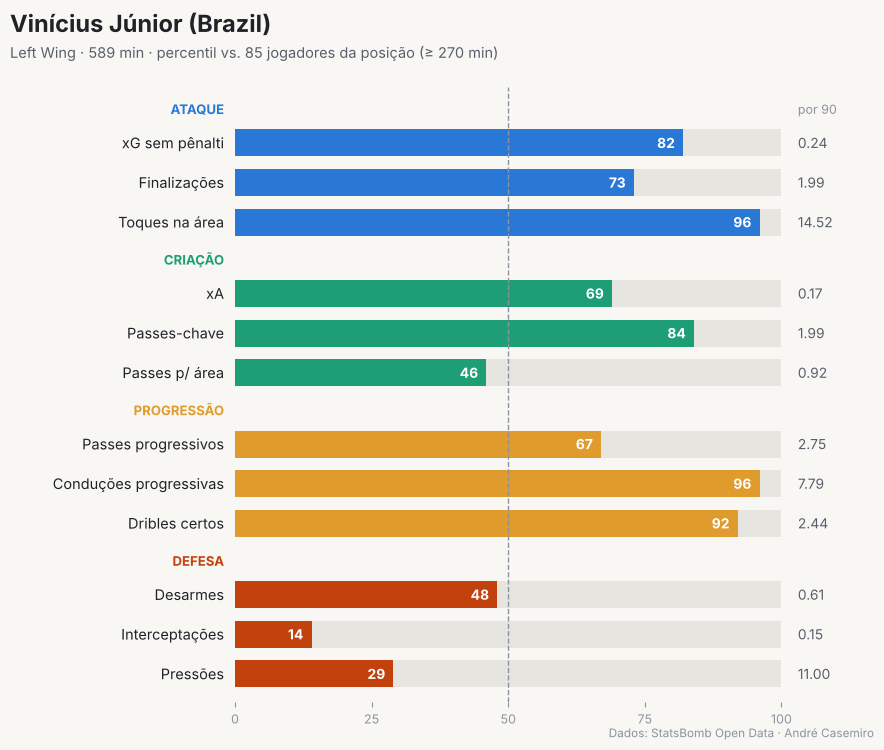

In [4]:
pontas = pool(df, ["PON"], MIN_MIN)
fig = viz.percentile_bars(pontas, "Vinícius Júnior", save=FIG / "perfil_vinicius_junior.png")

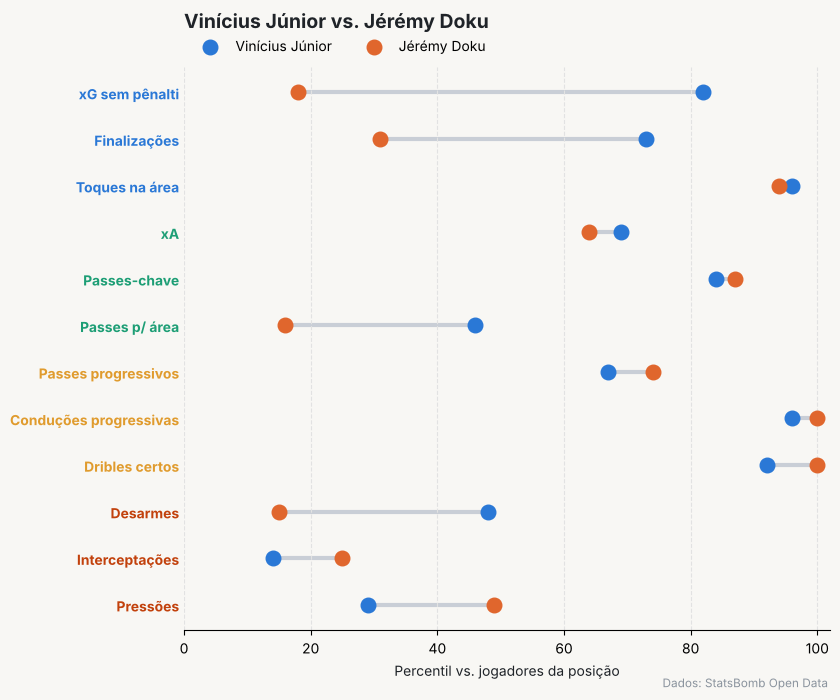

In [5]:
mais_parecido = similares_vini.loc[0, "player"]
fig = viz.compare_bars(pontas, "Vinícius Júnior", mais_parecido,
                        save=FIG / "comparacao_vinicius_similar.png")

**Leitura:** o modelo reúne pontas de **condução e 1x1** (muitas conduções progressivas, dribles certos e toques na área), e não pontas cruzadores. Isso bate com a percepção do jogo, o que é um bom sinal de que as métricas capturam o estilo.

## 3. Caso 2: centroavantes, volume de chances vs. eficiência

Um clube que procura um 9 quer quem **gera muitas chances** (xG/90 alto). Converter acima do xG em poucos jogos costuma ser variância, então o volume é o sinal mais confiável.

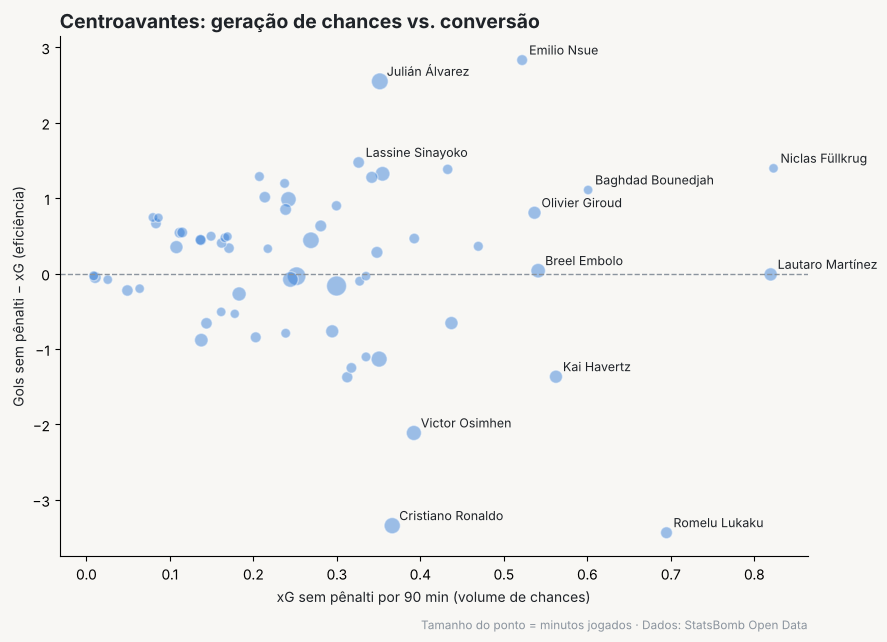

In [6]:
atacantes = pool(df, ["ATA"], MIN_MIN)
fig = viz.scatter_finishing(atacantes, save=FIG / "centroavantes_xg.png")

In [7]:
cols = ["player", "team", "minutes", "np_goals", "np_xg", "np_xg_p90", "np_xg_per_shot", "touches_box_p90"]
atacantes.sort_values("np_xg_p90", ascending=False)[cols].head(10).reset_index(drop=True)

,player,team,minutes,np_goals,np_xg,np_xg_p90,np_xg_per_shot,touches_box_p90
0,Niclas Füllkrug,Germany,285,4.0,2.60,0.82,0.15,24.03
1,Lautaro Martínez,Argentina,550,5.0,5.01,0.82,0.20,15.70
2,Romelu Lukaku,Belgium,445,0.0,3.44,0.69,0.21,21.64
3,Baghdad Bounedjah,Algeria,283,3.0,1.89,0.60,0.21,19.70
4,Kai Havertz,Germany,539,2.0,3.37,0.56,0.15,23.05
5,Breel Embolo,Switzerland,659,4.0,3.96,0.54,0.28,10.93
6,Olivier Giroud,France,535,4.0,3.19,0.54,0.17,14.29
7,Emilio Nsue,Equatorial Guinea,374,5.0,2.17,0.52,0.27,12.03
8,Habib Diallo,Senegal,314,2.0,1.64,0.47,0.33,13.47
9,Aleksandar Mitrović,Serbia,547,2.0,2.66,0.44,0.13,15.31


## 4. Caso 3: lista curta por filtros (volante construtor)

Pedido típico de comissão técnica: *"queremos um volante que construa o jogo: muitos passes, alta precisão e passes progressivos, sem deixar de recuperar bolas"*.

Filtro: percentil ≥ 60 em **passes tentados**, **% de passes certos** e **passes progressivos**, ordenado por **recuperações + interceptações**.

In [8]:
from src.similarity import percentiles
volantes = pool(df, ["VOL"], MIN_MIN)
pct = percentiles(volantes)
filtro = (pct["passes_p90"] >= 60) & (pct["pass_pct"] >= 60) & (pct["prog_passes_p90"] >= 60)
shortlist = (volantes[filtro]
             .assign(def_acoes_p90=lambda d: d["recoveries_p90"] + d["interceptions_p90"])
             .sort_values("def_acoes_p90", ascending=False)
             [["player", "team", "minutes", "passes_p90", "pass_pct", "prog_passes_p90", "def_acoes_p90"]]
             .reset_index(drop=True))
shortlist.head(10)

,player,team,minutes,passes_p90,pass_pct,prog_passes_p90,def_acoes_p90
0,Vitinha,Portugal,501,78.08,0.91,2.87,6.82
1,Bruno Guimarães,Brazil,440,57.24,0.90,2.86,6.75
2,Pierre-Emile Højbjerg,Denmark,677,69.37,0.89,4.78,6.64
3,Fabián Ruiz,Spain,579,67.91,0.89,4.04,6.22
4,Jerdy Schouten,Netherlands,537,54.95,0.93,4.36,5.70
5,Aurélien Tchouaméni,France,1196,64.03,0.92,3.08,4.89
6,Rúben Neves,Portugal,420,80.77,0.89,3.21,4.28
7,Leandro Paredes,Argentina,444,76.82,0.93,4.46,4.05
8,Robert Andrich,Germany,345,60.98,0.89,4.43,3.91
9,Granit Xhaka,Switzerland,909,63.97,0.90,4.16,3.57


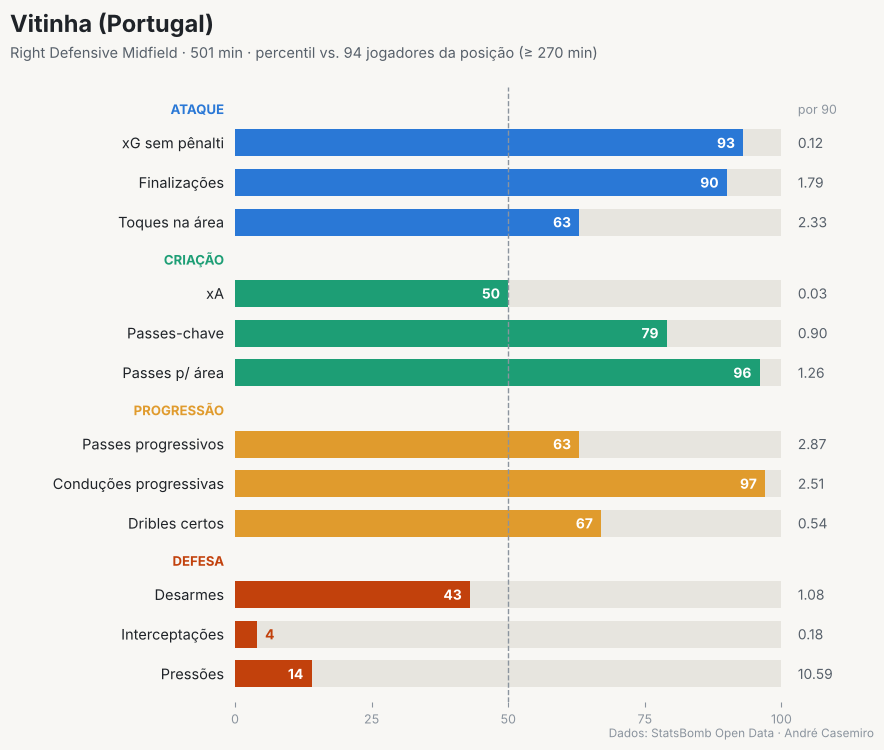

In [9]:
alvo = shortlist.loc[0, "player"]
fig = viz.percentile_bars(volantes, alvo, save=FIG / "perfil_volante_shortlist.png")

## 5. Limitações e próximos passos

- **Amostra:** torneios de seleções são curtos (3 a 7 jogos por atleta). Num clube, o ideal é usar uma temporada inteira de liga.
- **Contexto do time:** métricas defensivas dependem da posse do time. O próximo passo é **ajustar pela posse** (*possession-adjusted*).
- **Posição:** uso a posição mais frequente do atleta. Jogadores versáteis (ex.: Rodri como zagueiro na Copa 2022) podem cair no grupo "errado".
- **Próximas versões:** pesos por métrica definidos com a comissão técnica, clusterização de estilos (K-Means/UMAP) e um app em Streamlit para a busca interativa.